# Demo Random Forest: feature → validation → dự báo

Chạy Random Forest qua các cell quan sát được. Thuật toán và quy tắc chọn dùng lại source/config; không dùng dữ liệu test cho scaler hoặc chọn siêu tham số.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: C:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
OUT = demo_directory(PATHS, 'random_forest')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\random_forest_20261116_042007_06ef9da8


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Chuỗi, train/test và cấu hình
Xem trước cấu hình và quy tắc chọn. Default chạy lại toàn bộ grid; không hard-code ID đã chọn.

In [3]:
from source.forecasting import features
from source.forecasting.models import ml, random_forest as model
from source.forecasting.backtest import run_cross_validation
from source.forecasting.run_ml_forecast import summarize_candidates, forecast_frame
from source.forecasting.metrics import calculate_metrics
series = read_series(PATHS)
train = series.loc[series['split'].eq('train')].copy()
test = series.loc[series['split'].eq('test')].copy()
spec = json.loads((PROJECT_ROOT/'source/forecasting/configs/random_forest.json').read_text(encoding='utf-8'))
display(pd.DataFrame(spec['candidates']))
print(spec['selection'])
show_source(model.fit)


Matplotlib is building the font cache; this may take a moment.


,config_id,n_estimators,max_depth,min_samples_leaf,max_features,bootstrap,criterion,random_state,n_jobs
0,RF01,300,2,3,0.7,True,squared_error,42,1
1,RF02,300,2,3,1.0,True,squared_error,42,1
2,RF03,300,2,5,0.7,True,squared_error,42,1
3,RF04,300,2,5,1.0,True,squared_error,42,1
4,RF05,300,3,3,0.7,True,squared_error,42,1
5,RF06,300,3,3,1.0,True,squared_error,42,1
6,RF07,300,3,5,0.7,True,squared_error,42,1
7,RF08,300,3,5,1.0,True,squared_error,42,1


Within 1% of minimum mean validation RMSE, prefer shallower trees, larger leaves, then mean RMSE and config_id.


def fit(history, config):
    params = {key: value for key, value in config.items() if key != 'config_id'}
    return ml.fit(history, config, RandomForestRegressor(**params))

## Tạo 5 feature từ quá khứ
Mẫu đầu ở tháng thứ 8. Full train 64 mẫu; ba prefix CV 40/46/52. Nhãn và rolling không chứa tương lai.

In [4]:
growth = features.compute_log_growth(train.ev_total)
X,y,names = features.build_supervised_dataset(growth)
supervised = pd.DataFrame(X, columns=names)
supervised.insert(0,'date',train.date.iloc[7:].to_numpy())
supervised['target_log_growth'] = y
display(supervised.head(8))
display(pd.DataFrame([{'train_months':n,'supervised_rows':len(features.build_supervised_dataset(features.compute_log_growth(train.ev_total.iloc[:n]))[1])}
                      for n in [47,53,59,71]]))
assert X.shape==(64,5)
# Căn chỉ số mẫu đầu: label r[7], đầu vào chỉ từ r[1:7].
expected_first = [growth[6],growth[5],growth[4],np.mean(growth[4:7]),np.mean(growth[1:7])]
compare_values('First-row past-only alignment',X[0],expected_first)


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,target_log_growth
0,2017-08-31,0.022424,0.026505,0.025329,0.024753,0.026623,0.019365
1,2017-09-30,0.019365,0.022424,0.026505,0.022765,0.024767,0.023766
2,2017-10-31,0.023766,0.019365,0.022424,0.021852,0.024394,0.026138
3,2017-11-30,0.026138,0.023766,0.019365,0.023090,0.023921,0.020837
4,2017-12-31,0.020837,0.026138,0.023766,0.023580,0.023172,0.018834
5,2018-01-31,0.018834,0.020837,0.026138,0.021936,0.021894,0.032639
6,2018-02-28,0.032639,0.018834,0.020837,0.024103,0.023597,0.017998
7,2018-03-31,0.017998,0.032639,0.018834,0.023157,0.023369,0.024730


,train_months,supervised_rows
0,47,40
1,53,46
2,59,52
3,71,64


,check,passed,max_absolute_difference
0,First-row past-only alignment,True,0.0


## Validation chỉ trong train
True tính CV mới; False đọc lại bảng đã lưu và ghi rõ chế độ. Scaler của từng lượt fit nằm trong prefix.

In [5]:
RUN_GRID_SEARCH = True
if RUN_GRID_SEARCH:
    runs = [run_cross_validation(series,model.fit,model.forecast,config,return_forecasts=True) for config in spec['candidates']]
    cv = pd.concat([result[0] for result in runs],ignore_index=True)
    validation_forecasts = pd.concat([result[1] for result in runs],ignore_index=True)
    print('Validation recomputed from train prefixes.')
else:
    cv = pd.read_csv(PROJECT_ROOT/'results/forecasting/cv_random_forest.csv')
    validation_forecasts = pd.read_csv(PROJECT_ROOT/'results/forecasting/validation_forecasts_random_forest.csv')
    print('Showing saved validation; grid was NOT rerun in this cell.')
cv['n_supervised'] = cv['n_train_months'] - 7
display(cv[['config_id','fold','origin','rmse','status','warnings']])
scores, selected = summarize_candidates(cv,spec)
display(scores)
print('Locked config before test:',selected)


Validation recomputed from train prefixes.


,config_id,fold,origin,rmse,status,warnings
0,RF01,1,2020-11-30,337.539430,ok,[]
1,RF01,2,2021-05-31,805.588681,ok,[]
2,RF01,3,2021-11-30,1536.771723,ok,[]
3,RF02,1,2020-11-30,473.323261,ok,[]
4,RF02,2,2021-05-31,774.713879,ok,[]
...,...,...,...,...,...,...
19,RF07,2,2021-05-31,838.757952,ok,[]
20,RF07,3,2021-11-30,1576.052257,ok,[]
21,RF08,1,2020-11-30,479.578084,ok,[]
22,RF08,2,2021-05-31,902.837661,ok,[]


,config_id,n_estimators,max_depth,min_samples_leaf,max_features,bootstrap,...,selected,mean_rmse,mean_mae,mean_smape,mean_bias,within_tolerance
0,RF01,300,2,3,0.7,True,...,False,893.299945,771.276212,0.822794,-590.773339,False
1,RF02,300,2,3,1.0,True,...,False,902.148705,765.288411,0.821978,-611.751811,False
2,RF03,300,2,5,0.7,True,...,False,1023.085345,869.331560,0.949894,-363.639658,False
3,RF04,300,2,5,1.0,True,...,False,955.064183,807.951935,0.866149,-488.759809,False
4,RF05,300,3,3,0.7,True,...,True,814.141508,708.645838,0.762220,-531.654805,True
5,RF06,300,3,3,1.0,True,...,False,863.432904,742.500312,0.803858,-579.226111,False
6,RF07,300,3,5,0.7,True,...,False,1061.625439,902.940652,0.984091,-389.389655,False
7,RF08,300,3,5,1.0,True,...,False,1014.351077,862.888144,0.923025,-530.683302,False


Locked config before test: {'config_id': 'RF05', 'n_estimators': 300, 'max_depth': 3, 'min_samples_leaf': 3, 'max_features': 0.7, 'bootstrap': True, 'criterion': 'squared_error', 'random_state': 42, 'n_jobs': 1}


## Minh họa scaler ở một prefix
Dùng fold 1 để nhìn thấy số mẫu và thống kê được fit từ prefix, không từ 83 tháng.

In [6]:
prefix = train.iloc[:47].copy()
fold_artifact = model.fit(prefix,selected)
X_fold,y_fold,_ = features.build_supervised_dataset(features.compute_log_growth(prefix.ev_total))
fold_info = ml.describe(fold_artifact)
display(pd.DataFrame([{'n_prefix_months':47,'n_supervised':fold_info['n_supervised'],
                       'target_mean':fold_info['target_mean'],'target_scale':fold_info['target_scale'],
                       'x_standardized':fold_info['x_standardized']}]))
compare_values('Prefix target scaler mean/std',[fold_info['target_mean'],fold_info['target_scale']],
               [y_fold.mean(),y_fold.std(ddof=0)])
if fold_artifact['x_scaler'] is not None:
    display(pd.DataFrame(fold_artifact['x_scaler'].transform(X_fold),columns=names).head())
else:
    display(pd.DataFrame(X_fold,columns=names).head())
    print('RF/XGBoost giữ nguyên X; chỉ nhãn tăng trưởng được chuẩn hóa.')


,n_prefix_months,n_supervised,target_mean,target_scale,x_standardized
0,47,40,0.022748,0.010272,False


,check,passed,max_absolute_difference
0,Prefix target scaler mean/std,True,0.0


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6
0,0.022424,0.026505,0.025329,0.024753,0.026623
1,0.019365,0.022424,0.026505,0.022765,0.024767
2,0.023766,0.019365,0.022424,0.021852,0.024394
3,0.026138,0.023766,0.019365,0.023090,0.023921
4,0.020837,0.026138,0.023766,0.023580,0.023172


RF/XGBoost giữ nguyên X; chỉ nhãn tăng trưởng được chuẩn hóa.


## Fit cấu hình đã khóa trên full train
64 mẫu học. Xem estimator, scaler, warning và cỡ mô hình thực tế.

In [7]:
artifact = model.fit(train,selected)
assert artifact['converged'] is not False
fitted_info = ml.describe(artifact)
display(artifact['estimator'])
display(pd.DataFrame([fitted_info]))
if artifact['x_scaler'] is not None:
    display(pd.DataFrame(artifact['x_scaler'].transform(X),columns=names).head())
display(pd.DataFrame({'target_r':y,'standardized_z':artifact['y_scaler'].transform(y.reshape(-1,1)).ravel()}).head())


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.7
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_l

,n_supervised,feature_names,x_standardized,x_mean,x_scale,target_mean,target_scale,target_variance,scaler_ddof,converged,warnings,feature_importances
0,64,"[r_lag_1, r_lag_2, r_lag_3, r_mean_3, r_mean_6]",False,None,None,0.023211,0.008738,0.000076,0,None,[],"[0.1942564759007409, 0.13035950460995144, 0.36..."


,target_r,standardized_z
0,0.019365,-0.440100
1,0.023766,0.063505
2,0.026138,0.334941
3,0.020837,-0.271724
4,0.018834,-0.500871


## Xem một bước dự báo và đổi ngược scaler
Tại gốc, đầu vào chỉ có tăng trưởng lịch sử. Không kẹp r âm về 0.

In [8]:
row = features.extract_features_at_step(growth)
z_one,r_one = ml.predict_growth(artifact,row)
level_one = float(train.ev_total.iloc[-1]*np.exp(r_one))
display(pd.DataFrame([dict(zip(names,row),z_pred=z_one,r_pred=r_one,pred=level_one)]))


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,pred
0,0.031478,0.033105,0.016176,0.02692,0.026017,-0.280851,0.020757,115316.959299


## Dự báo đệ quy 12 bước và trace
Bước 2 dùng r_pred bước 1; actual test chỉ ghép vào sau khi sinh đủ 12 dự báo.

,check,passed,max_absolute_difference
0,Step 2 lag uses predicted growth,True,0.0


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,horizon,pred
0,2022-12-31,0.031478,0.033105,0.016176,0.026920,0.026017,-0.280851,0.020757,1,115316.959299
1,2023-01-31,0.020757,0.031478,0.033105,0.028447,0.025839,0.260696,0.025489,2,118294.057830
2,2023-02-28,0.025489,0.020757,0.031478,0.025908,0.025549,0.413499,0.026824,3,121510.147688
3,2023-03-31,0.026824,0.025489,0.020757,0.024357,0.025638,-0.086712,0.022453,4,124269.319966
4,2023-04-30,0.022453,0.026824,0.025489,0.024922,0.026684,0.230091,0.025222,5,127443.452454
5,2023-05-31,0.025222,0.022453,0.026824,0.024833,0.025371,0.375808,0.026495,6,130865.181296
6,2023-06-30,0.026495,0.025222,0.022453,0.024723,0.024540,-0.028570,0.022961,7,133904.794379
7,2023-07-31,0.022961,0.026495,0.025222,0.024893,0.024907,0.283154,0.025685,8,137388.726873
8,2023-08-31,0.025685,0.022961,0.026495,0.025047,0.024940,0.386495,0.026588,9,141090.651221
9,2023-09-30,0.026588,0.025685,0.022961,0.025078,0.024901,-0.031121,0.022939,10,144364.553817


,date,actual,pred
0,2022-12-31,115665.0,115316.959299
1,2023-01-31,119377.0,118294.057830
2,2023-02-28,122322.0,121510.147688
3,2023-03-31,125478.0,124269.319966
4,2023-04-30,129728.0,127443.452454
5,2023-05-31,133975.0,130865.181296
6,2023-06-30,138353.0,133904.794379
7,2023-07-31,142537.0,137388.726873
8,2023-08-31,148730.0,141090.651221
9,2023-09-30,152690.0,144364.553817


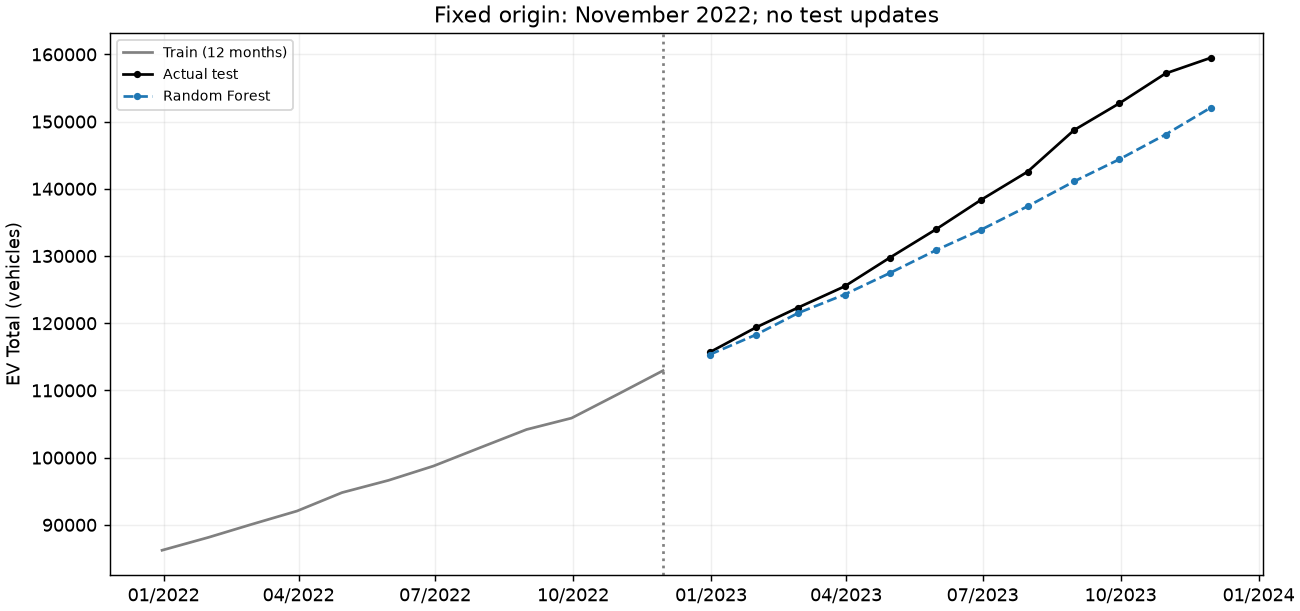

In [9]:
pred, rows = ml.forecast_with_trace(artifact,train,12)
trace = pd.DataFrame(rows)
trace.insert(0,'date',test.date.dt.strftime('%Y-%m-%d').to_numpy())
compare_values('Step 2 lag uses predicted growth',trace.loc[1,'r_lag_1'],trace.loc[0,'r_pred'])
forecast = forecast_frame('random_forest',selected['config_id'],test,pred)
display(trace)
display(forecast[['date','actual','pred']])
series_plot(train,test,{'Random Forest':pred})


## Chấm điểm và đối chiếu dự báo
Không dùng test để chọn lại config. Khoảng dự báo ML chưa được ước lượng, giữ trống.

In [10]:
metric = calculate_metrics(test.ev_total,pred)
display(pd.DataFrame([dict(model='Random Forest',**metric)]))
reference = pd.read_csv(PROJECT_ROOT/'results/forecasting/forecast_random_forest.csv')
compare_values('Random Forest forecast vs published result',pred,reference.pred)
assert forecast[['lower_95','upper_95','interval_level']].isna().all().all()
save_table(forecast,OUT/'forecast_random_forest.csv')
save_table(trace,OUT/'trace_random_forest.csv')
save_table(scores,OUT/'candidate_scores_random_forest.csv')
save_table(cv,OUT/'cv_random_forest.csv')
save_table(validation_forecasts,OUT/'validation_forecasts_random_forest.csv')
save_json({'config':selected,'fit':fitted_info,'test_metrics':metric},OUT/'demo_fit.json')


,model,rmse,mae,smape,bias
0,Random Forest,5243.320964,4242.907515,2.959396,4242.907515


,check,passed,max_absolute_difference
0,Random Forest forecast vs published result,True,1.455192e-11


## Giới hạn diễn giải
Một gốc test 12 tháng không chứng minh ưu thế dài hạn. Các fold CV chồng lấn, không coi là mẫu độc lập. Nếu môi trường/dữ liệu đổi và kết quả lệch, giữ kết quả thật và kiểm tra nguyên nhân; không sửa số cho giống bảng cũ.